In [1]:
# ============================================================
# CELL 1: IMPORT LIBRARIES
# ============================================================

import re
import time
import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from xgboost import XGBClassifier

print("Libraries imported successfully!")

Libraries imported successfully!


# Load the dataset, inspect its structure and sample records, and check for missing values.

In [2]:
# ============================================================
# CELL 2: LOAD AND VALIDATE DATASET
# ============================================================

df = pd.read_csv("HateSpeechDataset.csv", low_memory=False)

print("Original dataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nSample records:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

Original dataset shape: (440906, 2)

Column names: ['Content', 'Label']

Sample records:


,Content,Label
0,denial of normal the con be asked to comment o...,1
1,just by being able to tweet this insufferable ...,1
2,that is retarded you too cute to be single tha...,1
3,thought of a real badass mongol style declarat...,1
4,afro american basho,1



Missing values:
Content    0
Label      0
dtype: int64


# Data Cleaning and Label Normalization
## Retain valid binary labels, remove empty text and duplicates, and check class distribution.

In [3]:
# ============================================================
# CELL 3: DATA CLEANING AND LABEL NORMALIZATION
# ============================================================

df = df[["Content", "Label"]].copy()

df["Label"] = pd.to_numeric(df["Label"], errors="coerce")

# Keep only binary labels
df = df.dropna(subset=["Content", "Label"])
df = df[df["Label"].isin([0, 1])].copy()
df["Label"] = df["Label"].astype("int8")

# Remove empty text and exact duplicate records
df["Content"] = df["Content"].astype(str).str.strip()
df = df[df["Content"].str.len() > 0]
df = df.drop_duplicates(subset=["Content"]).reset_index(drop=True)

print("Shape after cleaning:", df.shape)
print("\nClass distribution:")
print(df["Label"].value_counts().sort_index())

print("\nMissing values:")
print(df.isnull().sum())

Shape after cleaning: (417560, 2)

Class distribution:
Label
0    341506
1     76054
Name: count, dtype: int64

Missing values:
Content    0
Label      0
dtype: int64


# Exploratory Data Analysis
## Examine dataset structure, text lengths, and class distribution.

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 417560 entries, 0 to 417559
Data columns (total 2 columns):
 #   Column   Non-Null Count   Dtype
---  ------   --------------   -----
 0   Content  417560 non-null  str  
 1   Label    417560 non-null  int8 
dtypes: int8(1), str(1)
memory usage: 3.6 MB

Text length statistics:
count    417560.000000
mean        223.679292
std         277.639992
min           1.000000
25%          61.000000
50%         117.000000
75%         264.000000
max        9998.000000
Name: Content, dtype: float64


,Count
Label,
Non-hate,341506
Hate,76054


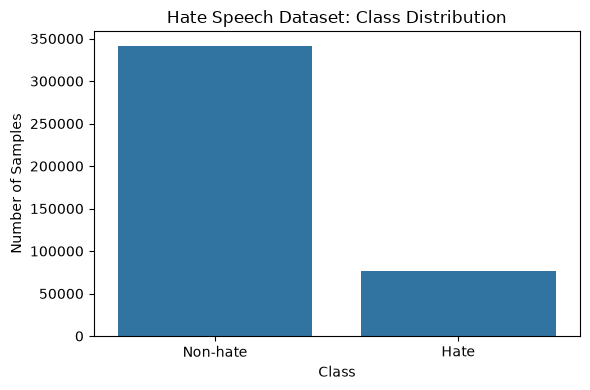

In [4]:
# ============================================================
# CELL 4: EXPLORATORY DATA ANALYSIS
# ============================================================

print("Dataset information:")
df.info()

print("\nText length statistics:")
print(df["Content"].str.len().describe())

display(
    df["Label"]
    .value_counts()
    .sort_index()
    .rename(index={0: "Non-hate", 1: "Hate"})
    .to_frame("Count")
)

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Label")
plt.xticks([0, 1], ["Non-hate", "Hate"])
plt.title("Hate Speech Dataset: Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

In [5]:
# ============================================================
# CELL 5: TEXT PREPROCESSING
# ============================================================

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["Cleaned_Content"] = df["Content"].apply(clean_text)

# Remove empty text
df = df[df["Cleaned_Content"].str.len() > 0].reset_index(drop=True)

print("Preprocessing completed.")
display(df[["Content", "Cleaned_Content", "Label"]].head())

print("\nNumber of labels:", df["Label"].nunique())
print("Labels:", sorted(df["Label"].unique()))

Preprocessing completed.


,Content,Cleaned_Content,Label
0,denial of normal the con be asked to comment o...,denial of normal the con be asked to comment o...,1
1,just by being able to tweet this insufferable ...,just by being able to tweet this insufferable ...,1
2,that is retarded you too cute to be single tha...,that is retarded you too cute to be single tha...,1
3,thought of a real badass mongol style declarat...,thought of a real badass mongol style declarat...,1
4,afro american basho,afro american basho,1



Number of labels: 2
Labels: [np.int8(0), np.int8(1)]


In [6]:
# ============================================================
# CELL 5B: HANDCRAFTED TEXT FEATURES
# ============================================================

def extract_text_features(texts):
    features = []

    for text in texts:
        text = str(text)

        words = re.findall(r"\b\w+\b", text)
        characters = len(text)
        word_count = len(words)

        features.append([
            characters,
            word_count,
            characters / max(word_count, 1),
            sum(c.isupper() for c in text) / max(characters, 1),
            sum(c.isdigit() for c in text) / max(characters, 1),
            sum(c in "!?.,;:" for c in text) / max(characters, 1),
            text.count("!") ,
            text.count("?"),
            len(re.findall(r"https?://\S+|www\.\S+", text)),
            len(re.findall(r"@\w+", text))
        ])

    return np.asarray(features, dtype=np.float32)


feature_names = [
    "character_count",
    "word_count",
    "average_word_length",
    "uppercase_ratio",
    "digit_ratio",
    "punctuation_ratio",
    "exclamation_count",
    "question_count",
    "url_count",
    "mention_count"
]

print("Handcrafted feature function ready.")
print("Features:", feature_names)

Handcrafted feature function ready.
Features: ['character_count', 'word_count', 'average_word_length', 'uppercase_ratio', 'digit_ratio', 'punctuation_ratio', 'exclamation_count', 'question_count', 'url_count', 'mention_count']


# Sampling and Train-Test Split
## Create a stratified sample and split it into training and testing sets.

In [7]:
# ============================================================
# CELL 6: SAMPLING AND TRAIN-TEST SPLIT
# ============================================================

SAMPLE_SIZE = min(200_000, len(df))

# Sample proportionally from each class
sample_parts = []

for label, group in df.groupby("Label"):
    n_samples = round(SAMPLE_SIZE * len(group) / len(df))

    sample_parts.append(
        group.sample(
            n=min(n_samples, len(group)),
            random_state=42
        )
    )

df_sample = (
    pd.concat(sample_parts, ignore_index=True)
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)

# Include raw text for handcrafted features
X = df_sample[["Content", "Cleaned_Content"]]
y = df_sample["Label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Sample shape:", df_sample.shape)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

Sample shape: (200000, 3)
Training samples: 160000
Testing samples: 40000

Training class distribution:
Label
0    130858
1     29142
Name: count, dtype: int64

Testing class distribution:
Label
0    32714
1     7286
Name: count, dtype: int64


# Handcrafted Text Feature Extraction
## Extract linguistic features such as text length, uppercase ratio, punctuation, URLs, and mentions for feature-based classification.

In [8]:
# ============================================================
# CELL 5B: HANDCRAFTED TEXT FEATURE EXTRACTION
# ============================================================

def extract_text_features(texts):
    features = []

    for text in texts:
        text = str(text)

        words = re.findall(r"\b\w+\b", text)
        char_count = len(text)
        word_count = len(words)

        features.append([
            char_count,
            word_count,
            char_count / max(word_count, 1),
            sum(c.isupper() for c in text) / max(char_count, 1),
            sum(c.isdigit() for c in text) / max(char_count, 1),
            sum(c in "!?.,;:" for c in text) / max(char_count, 1),
            text.count("!"),
            text.count("?"),
            len(re.findall(r"https?://\S+|www\.\S+", text)),
            len(re.findall(r"@\w+", text))
        ])

    return np.asarray(features, dtype=np.float32)


print("Handcrafted feature extraction function defined!")

Handcrafted feature extraction function defined!


# Feature-Engineered XGBoost Model
## Combine word-level TF-IDF, character-level TF-IDF, and handcrafted text features using a ColumnTransformer, then train an XGBoost classifier.

In [9]:
# ============================================================
# CELL 7: FEATURE-ENGINEERED XGBOOST MODEL
# ============================================================

feature_processor = ColumnTransformer(
    transformers=[
        (
            "word_tfidf",
            TfidfVectorizer(
                analyzer="word",
                ngram_range=(1, 2),
                max_features=5000,
                min_df=3,
                sublinear_tf=True,
                dtype=np.float32
            ),
            "Cleaned_Content"
        ),
        (
            "char_tfidf",
            TfidfVectorizer(
                analyzer="char_wb",
                ngram_range=(3, 4),
                max_features=3000,
                min_df=3,
                sublinear_tf=True,
                dtype=np.float32
            ),
            "Cleaned_Content"
        ),
        (
            "text_statistics",
            FunctionTransformer(
                extract_text_features,
                validate=False
            ),
            "Content"
        )
    ],
    remainder="drop"
)

model = Pipeline([
    ("features", feature_processor),
    ("classifier", XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        min_child_weight=3,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=2,
        scale_pos_weight=1,
        tree_method="hist",
        eval_metric="logloss",
        random_state=42,
        n_jobs=2
    ))
])

print("Feature-engineered model created.")

Feature-engineered model created.


In [10]:
# ============================================================
# CELL 8: MODEL TRAINING
# ============================================================

start_time = time.time()

model.fit(X_train, y_train)

training_time = (time.time() - start_time) / 60

print(f"Training completed in {training_time:.2f} minutes.")

Training completed in 1.23 minutes.


# Model-1 XGBoost Baseline Model

In [11]:
# ============================================================
# CELL 9: MODEL EVALUATION
# ============================================================

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("CLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Non-hate", "Hate"],
        digits=4,
        zero_division=0
    )
)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Macro F1: {f1_score(y_test, y_pred, average='macro'):.4f}")
print(f"Hate Precision: {precision_score(y_test, y_pred, pos_label=1, zero_division=0):.4f}")
print(f"Hate Recall: {recall_score(y_test, y_pred, pos_label=1, zero_division=0):.4f}")
print(f"Hate F1: {f1_score(y_test, y_pred, pos_label=1, zero_division=0):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob):.4f}")

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Non-hate     0.8438    0.9866    0.9096     32714
        Hate     0.7489    0.1801    0.2903      7286

    accuracy                         0.8397     40000
   macro avg     0.7963    0.5833    0.6000     40000
weighted avg     0.8265    0.8397    0.7968     40000

Accuracy: 0.8397
Macro F1: 0.6000
Hate Precision: 0.7489
Hate Recall: 0.1801
Hate F1: 0.2903
ROC-AUC: 0.8441


# Model-2 Class-Weighted XGBoost

In [12]:
# ============================================================
# NEXT CELL: CLASS-WEIGHTED XGBOOST
# ============================================================

from sklearn.base import clone
from sklearn.metrics import classification_report, roc_auc_score

negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

positive_weight = negative_count / positive_count

weighted_model = clone(model)

weighted_model.set_params(
    classifier__scale_pos_weight=positive_weight
)

start_time = time.time()
weighted_model.fit(X_train, y_train)

print(f"Training time: {(time.time() - start_time) / 60:.2f} minutes")
print("Positive class weight:", round(positive_weight, 3))

weighted_pred = weighted_model.predict(X_test)
weighted_prob = weighted_model.predict_proba(X_test)[:, 1]

print("\nCLASS-WEIGHTED XGBOOST REPORT")
print(classification_report(
    y_test,
    weighted_pred,
    labels=[0, 1],
    target_names=["Non-hate", "Hate"],
    digits=4,
    zero_division=0
))

print("ROC-AUC:", round(roc_auc_score(y_test, weighted_prob), 4))

Training time: 1.24 minutes
Positive class weight: 4.49

CLASS-WEIGHTED XGBOOST REPORT
              precision    recall  f1-score   support

    Non-hate     0.9391    0.7212    0.8158     32714
        Hate     0.3869    0.7901    0.5195      7286

    accuracy                         0.7337     40000
   macro avg     0.6630    0.7557    0.6677     40000
weighted avg     0.8385    0.7337    0.7619     40000

ROC-AUC: 0.836


# HyperParameter Tuning

In [13]:
# ============================================================
# HYPERPARAMETER TUNING — XGBOOST
# ============================================================

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.base import clone

param_distributions = {
    "classifier__n_estimators": [60, 100, 150],
    "classifier__max_depth": [2, 3, 4, 5],
    "classifier__learning_rate": [0.03, 0.05, 0.1],
    "classifier__min_child_weight": [1, 3, 5],
    "classifier__subsample": [0.7, 0.8, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 1.0],
    "classifier__reg_lambda": [1, 2, 5, 10]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

tuning_model = clone(model)

search = RandomizedSearchCV(
    estimator=tuning_model,
    param_distributions=param_distributions,
    n_iter=4,                 # Try 4 combinations initially
    scoring="f1",             # Optimize hate-class F1 (label 1)
    cv=cv,
    n_jobs=1,                 # Reduce memory pressure
    random_state=42,
    verbose=2,
    refit=True
)

start_time = time.time()
search.fit(X_train, y_train)

print(f"\nTuning time: {(time.time() - start_time) / 60:.2f} minutes")
print("\nBest parameters:")
print(search.best_params_)
print("\nBest cross-validation Hate F1:")
print(round(search.best_score_, 4))

best_model = search.best_estimator_

Fitting 3 folds for each of 4 candidates, totalling 12 fits
[CV] END classifier__colsample_bytree=1.0, classifier__learning_rate=0.05, classifier__max_depth=3, classifier__min_child_weight=3, classifier__n_estimators=60, classifier__reg_lambda=5, classifier__subsample=0.7; total time= 1.0min
[CV] END classifier__colsample_bytree=1.0, classifier__learning_rate=0.05, classifier__max_depth=3, classifier__min_child_weight=3, classifier__n_estimators=60, classifier__reg_lambda=5, classifier__subsample=0.7; total time= 1.0min
[CV] END classifier__colsample_bytree=1.0, classifier__learning_rate=0.05, classifier__max_depth=3, classifier__min_child_weight=3, classifier__n_estimators=60, classifier__reg_lambda=5, classifier__subsample=0.7; total time= 1.0min
[CV] END classifier__colsample_bytree=1.0, classifier__learning_rate=0.1, classifier__max_depth=2, classifier__min_child_weight=3, classifier__n_estimators=100, classifier__reg_lambda=2, classifier__subsample=0.7; total time=  59.5s
[CV] END

# Best Params from HyperParameter Tuning

In [14]:
# ============================================================
# BEST TUNED XGBOOST MODEL
# ============================================================

best_model = search.best_estimator_

print("Best parameters:")
print(search.best_params_)

print("\nBest cross-validation Hate F1:",
      round(search.best_score_, 4))

Best parameters:
{'classifier__subsample': 0.8, 'classifier__reg_lambda': 10, 'classifier__n_estimators': 150, 'classifier__min_child_weight': 5, 'classifier__max_depth': 5, 'classifier__learning_rate': 0.1, 'classifier__colsample_bytree': 0.7}

Best cross-validation Hate F1: 0.416


# Model-3 Tuned XGBoost Model

In [15]:
# ============================================================
# EVALUATE TUNED MODEL ON TEST DATA
# ============================================================

from sklearn.metrics import (
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

start_time = time.time()

tuned_pred = best_model.predict(X_test)
tuned_prob = best_model.predict_proba(X_test)[:, 1]

print(f"Prediction time: {(time.time() - start_time):.2f} seconds")

print("\nTUNED XGBOOST CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    tuned_pred,
    labels=[0, 1],
    target_names=["Non-hate", "Hate"],
    digits=4,
    zero_division=0
))

print("Accuracy:", round(accuracy_score(y_test, tuned_pred), 4))
print("Hate Precision:", round(precision_score(y_test, tuned_pred, pos_label=1, zero_division=0), 4))
print("Hate Recall:", round(recall_score(y_test, tuned_pred, pos_label=1, zero_division=0), 4))
print("Hate F1:", round(f1_score(y_test, tuned_pred, pos_label=1, zero_division=0), 4))
print("Macro F1:", round(f1_score(y_test, tuned_pred, average="macro"), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, tuned_prob), 4))

Prediction time: 19.84 seconds

TUNED XGBOOST CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Non-hate     0.8625    0.9764    0.9159     32714
        Hate     0.7394    0.3010    0.4278      7286

    accuracy                         0.8534     40000
   macro avg     0.8009    0.6387    0.6719     40000
weighted avg     0.8401    0.8534    0.8270     40000

Accuracy: 0.8534
Hate Precision: 0.7394
Hate Recall: 0.301
Hate F1: 0.4278
Macro F1: 0.6719
ROC-AUC: 0.8714


# Model-4 Combined Model: Class-Weighted + Tuned XGBoost

In [16]:

# ============================================================
# COMBINED MODEL: CLASS-WEIGHTED + TUNED XGBOOST
# ============================================================

from sklearn.base import clone
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import time

# Calculate class weight from training data only
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()
positive_weight = negative_count / positive_count

# Start with the original feature-engineered pipeline
combined_model = clone(model)

# Apply the best XGBoost hyperparameters found during tuning
combined_model.set_params(**search.best_params_)

# Add class weighting
combined_model.set_params(
    classifier__scale_pos_weight=positive_weight
)

print("Class weight:", round(positive_weight, 4))
print("Combined parameters:")
print(combined_model.get_params()["classifier"])

# Train
start_time = time.time()
combined_model.fit(X_train, y_train)

print(
    f"\nTraining time: "
    f"{(time.time() - start_time) / 60:.2f} minutes"
)

# Evaluate on the same test set
combined_pred = combined_model.predict(X_test)
combined_prob = combined_model.predict_proba(X_test)[:, 1]

print("\nCOMBINED CLASS-WEIGHTED + TUNED XGBOOST")
print(classification_report(
    y_test,
    combined_pred,
    labels=[0, 1],
    target_names=["Non-hate", "Hate"],
    digits=4,
    zero_division=0
))

print("Accuracy:", round(accuracy_score(y_test, combined_pred), 4))
print("Hate Precision:", round(
    precision_score(y_test, combined_pred, pos_label=1, zero_division=0), 4
))
print("Hate Recall:", round(
    recall_score(y_test, combined_pred, pos_label=1, zero_division=0), 4
))
print("Hate F1:", round(
    f1_score(y_test, combined_pred, pos_label=1, zero_division=0), 4
))
print("Macro F1:", round(
    f1_score(y_test, combined_pred, average="macro"), 4
))
print("ROC-AUC:", round(roc_auc_score(y_test, combined_prob), 4))


Class weight: 4.4904
Combined parameters:
XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.7, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=5, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=150, n_jobs=2,
              num_parallel_tree=None, ...)

Training time: 2.45 minutes

COMBINED CLASS-WEIGHTED + TUNED XGBOOST
              precision    recall  f1-score   support

    Non-hate     0.9447    0.7884    0.8595     32714
        Hate

# Comparison of Classification Models

In [18]:

# ============================================================
# COMPARISON: ALL 4 HATE-SPEECH CLASSIFICATION MODELS
# ============================================================

# Store predictions and probabilities from all five models
model_results = {
    "Baseline XGBoost": (y_pred, y_prob),
    "Class-Weighted XGBoost": (weighted_pred, weighted_prob),
    "Tuned XGBoost": (tuned_pred, tuned_prob),
    "Combined XGBoost": (combined_pred, combined_prob)
}

# Calculate evaluation metrics
comparison = []

for model_name, (pred, prob) in model_results.items():
    comparison.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, pred, zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, pred, average="macro",
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

comparison_df = pd.DataFrame(comparison)

# Display metrics rounded to four decimal places
print("=" * 100)
print("COMPARISON OF ALL FIVE MODELS")
print("=" * 100)

print(
    comparison_df
    .sort_values("Macro F1", ascending=False)
    .round(4)
    .to_string(index=False)
)

# Identify the best model for each metric
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "Macro F1",
    "ROC-AUC"
]

print("\n" + "=" * 100)
print("BEST MODEL FOR EACH METRIC")
print("=" * 100)

for metric in metrics:
    best_idx = comparison_df[metric].idxmax()
    best_name = comparison_df.loc[best_idx, "Model"]
    best_value = comparison_df.loc[best_idx, metric]

    print(f"{metric:<12}: {best_name} ({best_value:.4f})")

# Select the overall best model by Macro F1
best_idx = comparison_df["Macro F1"].idxmax()
best_name = comparison_df.loc[best_idx, "Model"]
best_score = comparison_df.loc[best_idx, "Macro F1"]

print("\n" + "=" * 100)
print(f"OVERALL BEST MODEL: {best_name}")
print(f"Macro F1-Score: {best_score:.4f}")
print("=" * 100)



COMPARISON OF ALL FIVE MODELS
                 Model  Accuracy  Precision  Recall  F1-Score  Macro F1  ROC-AUC
      Combined XGBoost    0.7892     0.4549  0.7926    0.5780    0.7188   0.8688
         Tuned XGBoost    0.8534     0.7394  0.3010    0.4278    0.6719   0.8714
Class-Weighted XGBoost    0.7337     0.3869  0.7901    0.5195    0.6677   0.8360
      Baseline XGBoost    0.8396     0.7489  0.1801    0.2903    0.6000   0.8441

BEST MODEL FOR EACH METRIC
Accuracy    : Tuned XGBoost (0.8534)
Precision   : Baseline XGBoost (0.7489)
Recall      : Combined XGBoost (0.7926)
F1-Score    : Combined XGBoost (0.5780)
Macro F1    : Combined XGBoost (0.7188)
ROC-AUC     : Tuned XGBoost (0.8714)

OVERALL BEST MODEL: Combined XGBoost
Macro F1-Score: 0.7188


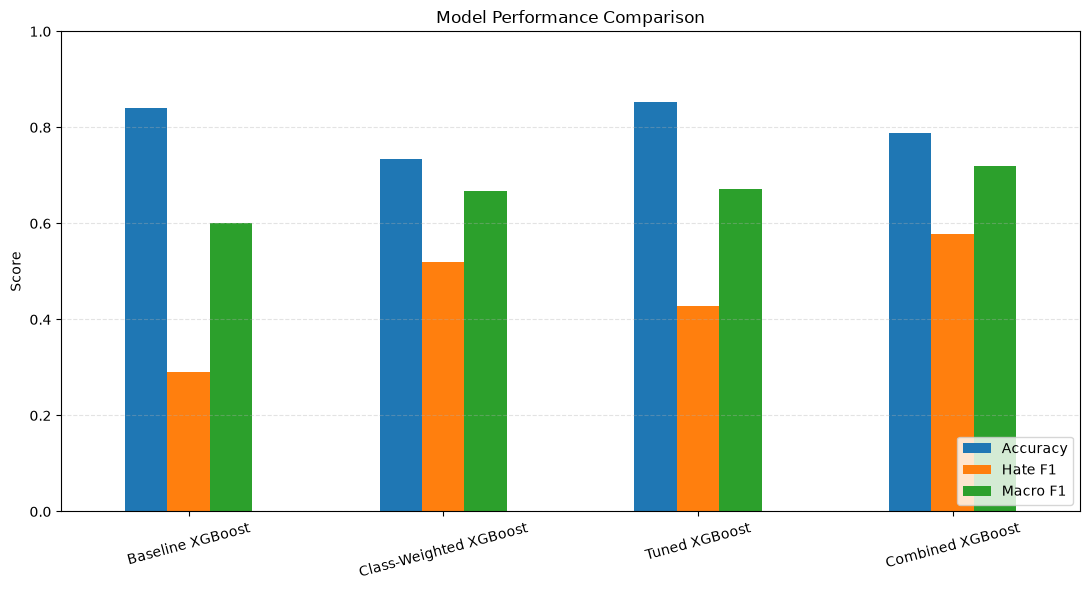

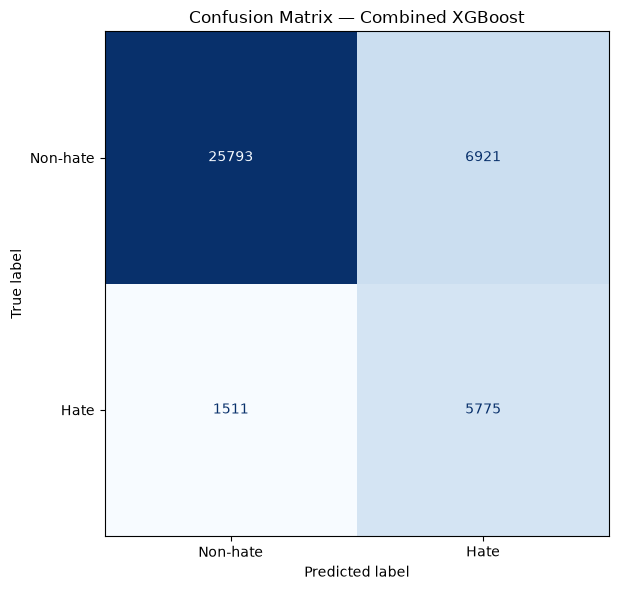

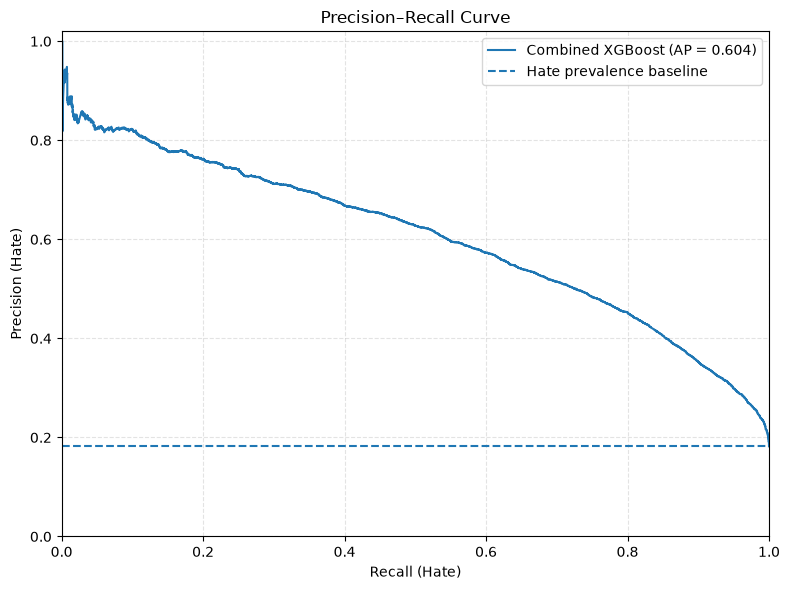

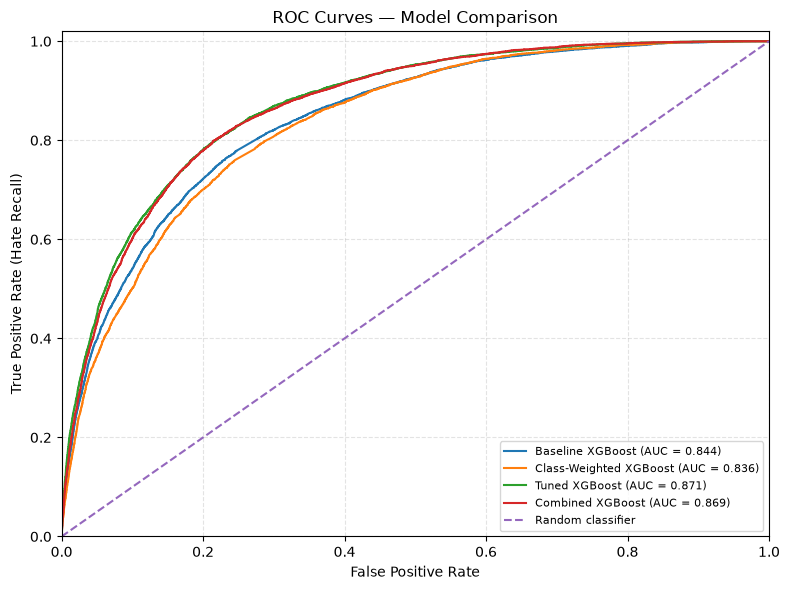

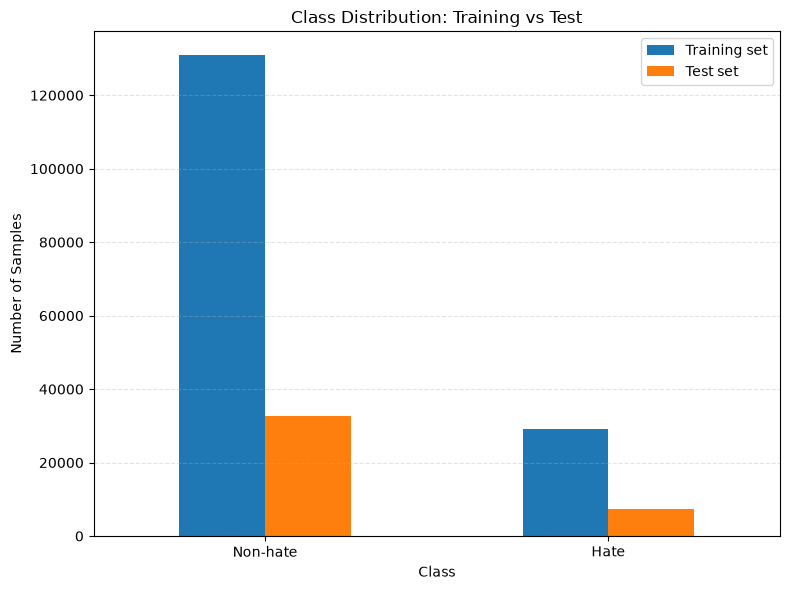


ALL 5 VISUALIZATIONS SAVED SUCCESSFULLY!
Folder: /home/ibm-user/HateSpeechProject/visualizations
 - 1_model_performance_comparison.png
 - 2_confusion_matrix.png
 - 3_precision_recall_curve.png
 - 4_roc_curves.png
 - 5_class_distribution.png


In [21]:

# ============================================================
# 5 ESSENTIAL VISUALIZATIONS: HATE-SPEECH CLASSIFICATION
# All images saved to ./visualizations/
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve, roc_curve,
    average_precision_score
)

# Create folder in the current Jupyter working directory
OUTPUT_DIR = os.path.join(os.getcwd(), "visualizations")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# MODEL RESULTS
# Assumes these prediction/probability variables already exist.
# ------------------------------------------------------------
model_results = {
    "Baseline XGBoost": (y_pred, y_prob),
    "Class-Weighted XGBoost": (weighted_pred, weighted_prob),
    "Tuned XGBoost": (tuned_pred, tuned_prob),
    "Combined XGBoost": (combined_pred, combined_prob)
}

# ============================================================
# GRAPH 1: MODEL PERFORMANCE COMPARISON
# ============================================================

rows = []

for name, (pred, prob) in model_results.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Hate F1": f1_score(y_test, pred, zero_division=0),
        "Macro F1": f1_score(
            y_test, pred, average="macro", zero_division=0
        )
    })

comparison_df = pd.DataFrame(rows)

ax = comparison_df.set_index("Model")[
    ["Accuracy", "Hate F1", "Macro F1"]
].plot(kind="bar", figsize=(11, 6), ylim=(0, 1), rot=15)

ax.set_title("Model Performance Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.legend(loc="lower right")

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "1_model_performance_comparison.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()
plt.close()


# Choose the model for the remaining individual graphs.
# If predictions for the weight=2.5 model exist, use them.
if "final_pred" in globals() and "final_prob" in globals():
    selected_name = "Tuned XGBoost (weight=2.5)"
    selected_pred, selected_prob = final_pred, final_prob
else:
    selected_name = "Combined XGBoost"
    selected_pred, selected_prob = combined_pred, combined_prob


# ============================================================
# GRAPH 2: CONFUSION MATRIX
# 0 = Non-hate, 1 = Hate
# ============================================================

cm = confusion_matrix(y_test, selected_pred, labels=[0, 1])

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-hate", "Hate"]
)
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)

ax.set_title(f"Confusion Matrix — {selected_name}")

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "2_confusion_matrix.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()
plt.close()


# ============================================================
# GRAPH 3: PRECISION-RECALL CURVE
# ============================================================

precision, recall, _ = precision_recall_curve(
    y_test, selected_prob
)
avg_precision = average_precision_score(y_test, selected_prob)
hate_prevalence = np.mean(np.asarray(y_test) == 1)

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    recall, precision,
    label=f"{selected_name} (AP = {avg_precision:.3f})"
)
ax.axhline(
    y=hate_prevalence,
    linestyle="--",
    label="Hate prevalence baseline"
)

ax.set_title("Precision–Recall Curve")
ax.set_xlabel("Recall (Hate)")
ax.set_ylabel("Precision (Hate)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.grid(True, linestyle="--", alpha=0.35)
ax.legend()

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "3_precision_recall_curve.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()
plt.close()


# ============================================================
# GRAPH 4: ROC CURVES FOR ALL MODELS
# ============================================================

fig, ax = plt.subplots(figsize=(8, 6))

for name, (pred, prob) in model_results.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)

    ax.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

ax.plot(
    [0, 1], [0, 1],
    linestyle="--", label="Random classifier"
)

ax.set_title("ROC Curves — Model Comparison")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate (Hate Recall)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.grid(True, linestyle="--", alpha=0.35)
ax.legend(loc="lower right", fontsize=8)

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "4_roc_curves.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()
plt.close()


# ============================================================
# GRAPH 5: CLASS DISTRIBUTION
# ============================================================

class_names = {0: "Non-hate", 1: "Hate"}

train_counts = (
    pd.Series(np.asarray(y_train))
    .map(class_names)
    .value_counts()
)
test_counts = (
    pd.Series(np.asarray(y_test))
    .map(class_names)
    .value_counts()
)

dist_df = pd.DataFrame({
    "Training set": train_counts,
    "Test set": test_counts
}).fillna(0).reindex(["Non-hate", "Hate"])

ax = dist_df.plot(kind="bar", figsize=(8, 6), rot=0)

ax.set_title("Class Distribution: Training vs Test")
ax.set_xlabel("Class")
ax.set_ylabel("Number of Samples")
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.legend()

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "5_class_distribution.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()
plt.close()


# ============================================================
# CONFIRM SAVED FILES
# ============================================================

print("\nALL 5 VISUALIZATIONS SAVED SUCCESSFULLY!")
print("Folder:", OUTPUT_DIR)

for filename in sorted(os.listdir(OUTPUT_DIR)):
    if filename.endswith(".png"):
        print(" -", filename)


In [ ]:

# ============================================================
# GRAPH 1: MODEL PERFORMANCE COMPARISON
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

performance_metrics = [
    "Accuracy", "F1-Score", "Macro F1", "ROC-AUC"
]

plot_df = comparison_df.set_index("Model")[performance_metrics]

ax = plot_df.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.set_title("Performance Comparison of Hate-Speech Models")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=20)
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:

# ============================================================
# GRAPH 2: PRECISION, RECALL AND F1 COMPARISON
# ============================================================

class_metrics = ["Precision", "Recall", "F1-Score"]

ax = comparison_df.set_index("Model")[class_metrics].plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.set_title("Precision, Recall and F1-Score by Model (Hate Class)")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="best")

plt.tight_layout()
plt.show()


In [ ]:
# ============================================================
# CELL 11: SAVE MODEL
# ============================================================

joblib.dump(model, "hatespeech_feature_engineered_xgb.pkl")

print("Model saved as hatespeech_feature_engineered_xgb.pkl")